In [3]:
# Common requirements: use Python, NumPy and Pandas; load the dataset; display head(), tail(), shape, info() and describe().
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('penguins_size.csv')
print(df.head())
print(df.tail())
print(df.shape)
print(df.info())
print(df.describe())

  studyName  Sample Number                              Species  Region  \
0   PAL0708              1  Adelie Penguin (Pygoscelis adeliae)  Anvers   
1   PAL0708              2  Adelie Penguin (Pygoscelis adeliae)  Anvers   
2   PAL0708              3  Adelie Penguin (Pygoscelis adeliae)  Anvers   
3   PAL0708              4  Adelie Penguin (Pygoscelis adeliae)  Anvers   
4   PAL0708              5  Adelie Penguin (Pygoscelis adeliae)  Anvers   

      Island               Stage Individual ID Clutch Completion  Date Egg  \
0  Torgersen  Adult, 1 Egg Stage          N1A1               Yes  11/11/07   
1  Torgersen  Adult, 1 Egg Stage          N1A2               Yes  11/11/07   
2  Torgersen  Adult, 1 Egg Stage          N2A1               Yes  11/16/07   
3  Torgersen  Adult, 1 Egg Stage          N2A2               Yes  11/16/07   
4  Torgersen  Adult, 1 Egg Stage          N3A1               Yes  11/16/07   

   Culmen Length (mm)  Culmen Depth (mm)  Flipper Length (mm)  Body Mass (g)  \


In [4]:
#Q.1:Count penguins by species and island.
print(df["Species"].value_counts())
print(" ")
print(df["Island"].value_counts())

Species
Adelie Penguin (Pygoscelis adeliae)          152
Gentoo penguin (Pygoscelis papua)            124
Chinstrap penguin (Pygoscelis antarctica)     68
Name: count, dtype: int64
 
Island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64


In [11]:
#Q.2:Find average body mass and flipper length by species.
print(df.groupby("Species")[["Body Mass (g)", "Flipper Length (mm)"]].mean())

                                           Body Mass (g)  Flipper Length (mm)
Species                                                                      
Adelie Penguin (Pygoscelis adeliae)          3700.662252           189.953642
Chinstrap penguin (Pygoscelis antarctica)    3733.088235           195.823529
Gentoo penguin (Pygoscelis papua)            5076.016260           217.186992


In [16]:
#Q.3:Which species has the highest average body mass?
avg_body_mass = df.groupby("Species")["Body Mass (g)"].mean()
print(avg_body_mass.idxmax())
print(avg_body_mass.max())

Gentoo penguin (Pygoscelis papua)
5076.016260162602


In [18]:
#Q.4:Compare average bill length by species.
print(df.groupby("Species")["Culmen Length (mm)"].mean())

Species
Adelie Penguin (Pygoscelis adeliae)          38.791391
Chinstrap penguin (Pygoscelis antarctica)    48.833824
Gentoo penguin (Pygoscelis papua)            47.504878
Name: Culmen Length (mm), dtype: float64


In [20]:
#Q.5:Check and report missing values in sex and measurement columns.
df[['Sex','Culmen Length (mm)', 'Culmen Depth (mm)', 'Flipper Length (mm)', 'Body Mass (g)']].isnull().sum()

Sex                    10
Culmen Length (mm)      2
Culmen Depth (mm)       2
Flipper Length (mm)     2
Body Mass (g)           2
dtype: int64

In [24]:
#Q.6:Find the 10 penguins with the greatest body mass.
print(df.sort_values("Body Mass (g)", ascending=False).head(10))

    studyName  Sample Number                            Species  Region  \
237   PAL0708             18  Gentoo penguin (Pygoscelis papua)  Anvers   
253   PAL0708             34  Gentoo penguin (Pygoscelis papua)  Anvers   
297   PAL0809             78  Gentoo penguin (Pygoscelis papua)  Anvers   
337   PAL0910            118  Gentoo penguin (Pygoscelis papua)  Anvers   
331   PAL0910            112  Gentoo penguin (Pygoscelis papua)  Anvers   
299   PAL0809             80  Gentoo penguin (Pygoscelis papua)  Anvers   
335   PAL0910            116  Gentoo penguin (Pygoscelis papua)  Anvers   
235   PAL0708             16  Gentoo penguin (Pygoscelis papua)  Anvers   
233   PAL0708             14  Gentoo penguin (Pygoscelis papua)  Anvers   
295   PAL0809             76  Gentoo penguin (Pygoscelis papua)  Anvers   

     Island               Stage Individual ID Clutch Completion  Date Egg  \
237  Biscoe  Adult, 1 Egg Stage         N39A2               Yes  11/27/07   
253  Biscoe  Adult, 

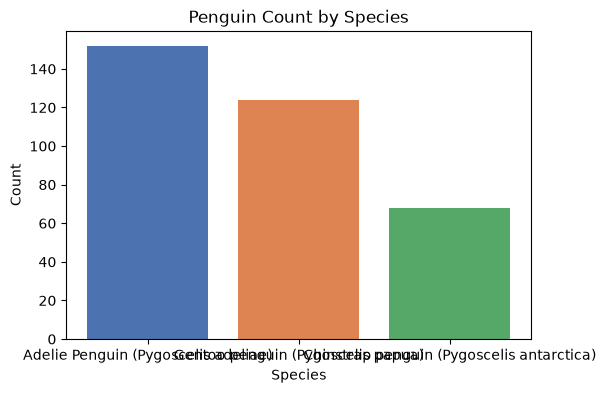

C:\Users\Safdar raza\AppData\Local\Temp\ipykernel_11904\4162042907.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


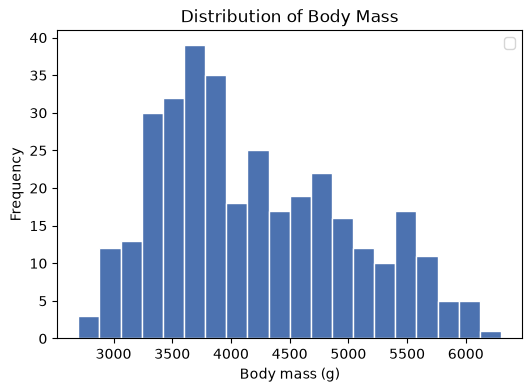

In [33]:
#Make a species-count bar chart and a body-mass histogram.
counts = df["Species"].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color=["#4c72b0", "#dd8452", "#55a868"])
plt.title("Penguin Count by Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(df["Body Mass (g)"], bins=20, color="#4c72b0", edgecolor="white")
plt.title("Distribution of Body Mass")
plt.xlabel("Body mass (g)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [35]:
#NumPy calculations
mass = df["Body Mass (g)"].dropna().to_numpy()
print("NumPy mean   :", np.mean(mass))
print("NumPy median :", np.median(mass))
print("NumPy std    :", np.std(mass))

NumPy mean   : 4201.754385964912
NumPy median : 4050.0
NumPy std    : 800.781229238452


In [38]:
#Pandas filtering example
df[(df["Species"] == "Gentoo penguin (Pygoscelis papua)") & (df["Body Mass (g)"] > 5500)]

,studyName,Sample Number,Species,Region,Island,Stage,Individual ID,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),Comments
221,PAL0708,2,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N31A2,Yes,11/27/07,50.0,16.3,230.0,5700.0,MALE,8.14756,-25.39369,NaN
223,PAL0708,4,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N32A2,Yes,11/27/07,50.0,15.2,218.0,5700.0,MALE,8.25540,-25.40075,NaN
231,PAL0708,12,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N36A2,No,11/27/07,49.0,16.1,216.0,5550.0,MALE,8.10417,-25.50562,NaN
233,PAL0708,14,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N37A2,Yes,11/29/07,48.4,14.6,213.0,5850.0,MALE,7.82080,-25.48025,NaN
235,PAL0708,16,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N38A2,Yes,12/3/07,49.3,15.7,217.0,5850.0,MALE,8.07137,-25.52473,NaN
237,PAL0708,18,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N39A2,Yes,11/27/07,49.2,15.2,221.0,6300.0,MALE,8.27376,-25.00169,NaN
240,PAL0708,21,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N41A1,Yes,11/27/07,50.2,14.3,218.0,5700.0,MALE,7.89620,-25.37746,NaN
247,PAL0708,28,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N46A2,Yes,11/29/07,47.8,15.0,215.0,5650.0,MALE,7.92358,-25.48383,NaN
249,PAL0708,30,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N47A2,Yes,11/29/07,50.0,15.3,220.0,5550.0,MALE,8.30515,-25.19017,NaN
253,PAL0708,34,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N56A2,Yes,12/3/07,59.6,17.0,230.0,6050.0,MALE,7.76843,-25.68210,NaN


In [ ]:
#Three Observations:
#1. The species with the highest average body mass is the Gentoo penguin (Pygoscelis papua) with an average body mass of 5076.0 grams.
#2. The average bill length varies by species, with the Gentoo penguin having the longest average bill length of 47.5 mm, followed by the Chinstrap penguin (Pygoscelis antarcticus) with 39.2 mm, and the Adélie penguin (Pygoscelis adeliae) with 38.6 mm.
#3. There are missing values in the 'Sex' column (11 missing), 'Culmen Length (mm)' column (2 missing), 'Culmen Depth (mm)' column (2 missing), 'Flipper Length (mm)' column (1 missing), and 'Body Mass (g)' column (1 missing).